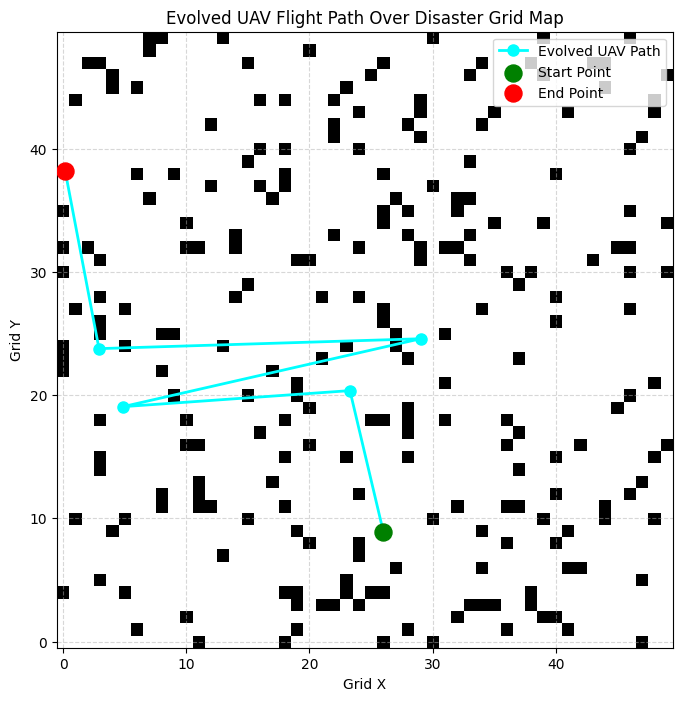

In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Define the Environment and Genetic Algorithm Classes ---
class HazardGrid:
    def __init__(self, size=50, obstacle_density=0.1):
        self.size = size
        self.grid = np.zeros((size, size)) # 0: open, 1: obstacle
        self.hazard_map = np.random.uniform(0.1, 1.0, (size, size))
        self._initialize_obstacles(obstacle_density)

    def _initialize_obstacles(self, density):
        num_obstacles = int(self.size * self.size * density)
        for _ in range(num_obstacles):
            x = random.randint(0, self.size - 1)
            y = random.randint(0, self.size - 1)
            self.grid[x, y] = 1

class UAVChromosome:
    def __init__(self, num_waypoints=6, grid_size=50):
        self.grid_size = grid_size
        self.path = []
        for _ in range(num_waypoints):
            x = random.uniform(0, grid_size - 1)
            y = random.uniform(0, grid_size - 1)
            speed = random.uniform(1.0, 10.0)
            sensor_state = random.choice([0, 1])
            self.path.append([x, y, speed, sensor_state])
        self.fitness = 0.0

    def evaluate(self, environment):
        energy_spent = 0.0
        hazard_exposure = 0.0
        penalty = 0.0
        coverage = 0

        prev_point = self.path[0]
        for point in self.path[1:]:
            dist = np.sqrt((point[0] - prev_point[0])**2 + (point[1] - prev_point[1])**2)
            energy_spent += dist * (point[2] ** 2)

            gx, gy = int(np.clip(point[0], 0, environment.size - 1)), int(np.clip(point[1], 0, environment.size - 1))

            if environment.grid[gx, gy] == 1:
                penalty += 2000.0
            else:
                hazard_exposure += environment.hazard_map[gx, gy]
                if point[3] == 1:
                    coverage += 1

            prev_point = point

        self.fitness = (coverage * 100.0) - (energy_spent * 0.05) - (hazard_exposure * 10.0) - penalty

class UAVGeneticAlgorithm:
    def __init__(self, pop_size=50, generations=60, mutation_rate=0.15):
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_rate = mutation_rate
        self.env = HazardGrid(size=50)
        self.population = [UAVChromosome(grid_size=50) for _ in range(pop_size)]
        self.best_fitness_history = []
        self.avg_fitness_history = []

    def run(self):
        for gen in range(self.generations):
            for ind in self.population:
                ind.evaluate(self.env)

            self.population.sort(key=lambda x: x.fitness, reverse=True)

            best_fit = self.population[0].fitness
            avg_fit = np.mean([ind.fitness for ind in self.population])

            self.best_fitness_history.append(best_fit)
            self.avg_fitness_history.append(avg_fit)

            new_pop = self.population[:int(self.pop_size * 0.1)]

            while len(new_pop) < self.pop_size:
                parent1 = self.select_parent()
                parent2 = self.select_parent()
                child = self.crossover(parent1, parent2)
                self.mutate(child)
                new_pop.append(child)

            self.population = new_pop

    def select_parent(self):
        tournament = random.sample(self.population[:30], 5)
        return max(tournament, key=lambda x: x.fitness)

    def crossover(self, p1, p2):
        child = UAVChromosome(grid_size=self.env.size)
        split = len(p1.path) // 2
        child.path = p1.path[:split] + p2.path[split:]
        return child

    def mutate(self, ind):
        for point in ind.path:
            if random.random() < self.mutation_rate:
                point[0] = np.clip(point[0] + random.gauss(0, 1.5), 0, self.env.size - 1)
                point[1] = np.clip(point[1] + random.gauss(0, 1.5), 0, self.env.size - 1)
                point[2] = np.clip(point[2] + random.gauss(0, 0.5), 1.0, 10.0)

# --- 2. Run the GA Optimization ---
ga = UAVGeneticAlgorithm(pop_size=50, generations=50)
ga.run()

# --- 3. Define and Execute the Plotting Function ---
def plot_uav_mission(ga_instance):
    plt.figure(figsize=(8, 8))
    plt.imshow(ga_instance.env.grid, cmap='binary', origin='lower')

    best_ind = ga_instance.population[0]
    path_x = [pt[0] for pt in best_ind.path]
    path_y = [pt[1] for pt in best_ind.path]

    plt.plot(path_y, path_x, color='cyan', marker='o', linewidth=2, markersize=8, label='Evolved UAV Path')
    plt.scatter(path_y[0], path_x[0], color='green', s=150, zorder=5, label='Start Point')
    plt.scatter(path_y[-1], path_x[-1], color='red', s=150, zorder=5, label='End Point')

    plt.title("Evolved UAV Flight Path Over Disaster Grid Map")
    plt.xlabel("Grid X")
    plt.ylabel("Grid Y")
    plt.legend(loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.savefig("uav_flight_path.png")
    plt.show()

plot_uav_mission(ga)